<a href="https://colab.research.google.com/github/fzh05/Decicion-Making/blob/main/Olah_Data_Final_DM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perbandingan Random Forest, XGBoost, dan SVM untuk Klasifikasi Intensitas Curah Hujan Hari Berikutnya di DAS Way Sekampung

**Penulis:** Afifah Fauziah (NIM 123450002), Nadia Faraj Alyafaatin Simbolon, M. Syamsuddin Wisnubroto, S.Si., M.Si., Indah Suciati, S.Mat., M.Mat.
Program Studi Sains Data, Institut Teknologi Sumatera

Notebook ini mengikuti alur Bab 2 (Metode) dan Bab 3 (Hasil) pada draf jurnal:

| Bagian notebook | Bagian jurnal |
|---|---|
| 1. Konfigurasi | 2.1 |
| 2. Unduh data | 2.1 |
| 3. Pembersihan data | 2.2, Tabel 1 |
| 4. Eksplorasi | 3.1 |
| 5. Rekayasa fitur (24 fitur) | 2.3 |
| 6. Target 4 kelas (t+1) | 2.4 |
| 7. Pembagian kronologis | 2.5, Tabel 2 |
| 8. Pelatihan model | 2.6 |
| 9. Evaluasi dan pemilihan model | 2.7, 3.2, Tabel 3 |
| 10. Kinerja per kelas | 3.3, Tabel 4 |
| 11. Distribusi antarperiode | 3.4 |
| 12. Kepentingan fitur | 3.5 |
| 13. Simpan hasil | - |

## 1. Konfigurasi dan impor pustaka

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import requests
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.width", 160)

import sklearn
print("scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__, "| pandas", pd.__version__)  # cocokkan dengan Subbab 2.6

# ---------- Konstanta penelitian (Subbab 2.1 - 2.6) ----------
SEED = 42
RAW_DIR, OUT_DIR = "data_raw", "output"
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Tiga titik grid NASA POWER: hulu, tengah, hilir (nama_titik: (lat, lon))
POINTS = {
    "hulu_batutegi":    (-5.05, 104.85),
    "tengah_argoguruh": (-5.16, 105.11),
    "hilir_sekampung":  (-5.45, 105.60),
}
ZONA = {"hulu_batutegi": "hulu", "tengah_argoguruh": "tengah", "hilir_sekampung": "hilir"}
ZONES = ["hulu", "tengah", "hilir"]

START_YEAR, END_YEAR = 2015, 2025
# IMERG_PRECTOT tidak diminta: seluruh nilainya kosong (-999) pada titik ini
VARS = ["PRECTOTCORR", "GWETTOP", "T2M_MAX", "T2M_MIN", "WS2M", "PS"]
BASE_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

# Ambang BMKG (mm/hari) pada hujan maksimum antarzona hari t+1
BINS = [-np.inf, 5, 20, 50, np.inf]
CLASS_NAMES = ["0: Tidak/sangat ringan (<5 mm)", "1: Ringan (5-20 mm)",
               "2: Sedang (20-50 mm)", "3: Lebat (>=50 mm)"]
MIN_TRAIN_TOP = 30          # gabungkan kelas teratas jika sampel latih < 30
API_K = 0.9                 # koefisien peluruhan Antecedent Precipitation Index

# Pembagian kronologis (Subbab 2.5)
TRAIN_END, VAL_END = "2022-12-31", "2023-12-31"

scikit-learn 1.6.1 | xgboost 3.4.1 | pandas 2.2.3


## 2. Unduh data NASA POWER (Subbab 2.1)

Data diunduh per titik melalui API harian NASA POWER (komunitas AG), 1 Jan 2015 - 31 Des 2025 (4.018 hari per titik).
Jika berkas sudah ada di `data_raw/`, berkas tersebut dipakai kembali (cache), sehingga sel ini aman dijalankan ulang.

In [2]:
def download_point(name, lat, lon):
    path = f"{RAW_DIR}/power_{name}_{START_YEAR}_{END_YEAR}.csv"
    if os.path.exists(path):
        print(f"[cache] {path}")
        return pd.read_csv(path, parse_dates=["date"])

    params = {
        "parameters": ",".join(VARS), "community": "AG",
        "longitude": lon, "latitude": lat,
        "start": f"{START_YEAR}0101", "end": f"{END_YEAR}1231", "format": "JSON",
    }
    print(f"[unduh] {name} ({lat}, {lon}) ...")
    for attempt in range(3):
        try:
            resp = requests.get(BASE_URL, params=params, timeout=120)
            resp.raise_for_status()
            break
        except requests.RequestException as e:
            if attempt == 2:
                raise RuntimeError(f"Gagal mengunduh {name}: {e}") from e
            time.sleep(5)

    df = pd.DataFrame(resp.json()["properties"]["parameter"])
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df = df.rename_axis("date").reset_index()
    df["lokasi"], df["lat"], df["lon"] = name, lat, lon
    df.to_csv(path, index=False)
    time.sleep(1)                      # sopan terhadap API
    return df

raw = pd.concat([download_point(n, la, lo) for n, (la, lo) in POINTS.items()],
                ignore_index=True)
raw["zona"] = raw["lokasi"].map(ZONA)
raw = raw.drop(columns=[c for c in raw.columns if c == "IMERG_PRECTOT"])   # kosong, dikeluarkan
raw = raw[["date", "zona", "lat", "lon"] + VARS]
raw.to_csv(f"{RAW_DIR}/power_gabungan_semua_titik.csv", index=False)
print("Total baris:", len(raw))
raw.head()

[unduh] hulu_batutegi (-5.05, 104.85) ...
[unduh] tengah_argoguruh (-5.16, 105.11) ...
[unduh] hilir_sekampung (-5.45, 105.6) ...
Total baris: 12054


,date,zona,lat,lon,PRECTOTCORR,GWETTOP,T2M_MAX,T2M_MIN,WS2M,PS
0,2015-01-01,hulu,-5.05,104.85,11.38,0.88,28.81,21.85,0.95,99.62
1,2015-01-02,hulu,-5.05,104.85,31.73,0.92,29.12,22.24,0.93,99.68
2,2015-01-03,hulu,-5.05,104.85,10.96,0.89,27.95,22.76,0.94,99.70
3,2015-01-04,hulu,-5.05,104.85,7.42,0.88,29.38,21.36,0.85,99.61
4,2015-01-05,hulu,-5.05,104.85,1.28,0.86,30.77,21.62,0.80,99.56


## 3. Pembersihan data (Subbab 2.2)

Pemeriksaan: nilai penanda hilang (-999), duplikasi lokasi-tanggal, kelengkapan hari, dan validasi fisik.
Interpolasi linear (celah maksimum 3 hari) hanya dipakai bila ada nilai hilang.

In [3]:
# 1) Audit awal
print("Baris per zona:\n", raw.groupby("zona").size(), "\n")
print("Jumlah -999 per variabel:\n", (raw[VARS] == -999).sum(), "\n")
n_dup = int(raw.duplicated(["zona", "date"]).sum())
print("Duplikasi (zona, tanggal):", n_dup)
assert n_dup == 0, "Ada duplikasi zona-tanggal"

# 2) -999 -> NaN, lalu interpolasi linear (maks. 3 hari) per zona
raw = raw.sort_values(["zona", "date"]).reset_index(drop=True)
raw[VARS] = raw[VARS].replace(-999.0, np.nan)
n_nan_awal = int(raw[VARS].isna().sum().sum())
raw[VARS] = (raw.groupby("zona")[VARS]
                .transform(lambda s: s.interpolate(method="linear", limit=3)))
n_nan_akhir = int(raw[VARS].isna().sum().sum())
print(f"NaN sebelum: {n_nan_awal} | sesudah interpolasi: {n_nan_akhir}")
assert n_nan_akhir == 0, "Masih ada nilai hilang > 3 hari berturut-turut, periksa data."

# 3) Validasi fisik
print("\nValidasi fisik:")
print("  GWETTOP di luar 0-1     :", int(((raw.GWETTOP < 0) | (raw.GWETTOP > 1)).sum()))
print("  T2M_MAX < T2M_MIN       :", int((raw.T2M_MAX < raw.T2M_MIN).sum()))
print("  Hujan negatif           :", int((raw.PRECTOTCORR < 0).sum()))

Baris per zona:
 zona
hilir     4018
hulu      4018
tengah    4018
dtype: int64 

Jumlah -999 per variabel:
 PRECTOTCORR    0
GWETTOP        0
T2M_MAX        0
T2M_MIN        0
WS2M           0
PS             0
dtype: int64 

Duplikasi (zona, tanggal): 0
NaN sebelum: 0 | sesudah interpolasi: 0

Validasi fisik:
  GWETTOP di luar 0-1     : 0
  T2M_MAX < T2M_MIN       : 0
  Hujan negatif           : 0


In [4]:
# 4) Kesamaan titik hulu dan tengah (indikasi satu sel grid yang sama)
def pv(var):
    return raw.pivot(index="date", columns="zona", values=var)[ZONES]

rows = []
for v in VARS:
    w = pv(v)
    rows.append({"variabel": v,
                 "hulu == tengah (%)": 100 * (w["hulu"] == w["tengah"]).mean(),
                 "hulu == hilir (%)":  100 * (w["hulu"] == w["hilir"]).mean()})
pd.DataFrame(rows).round(1)

,variabel,hulu == tengah (%),hulu == hilir (%)
0,PRECTOTCORR,100.0,3.0
1,GWETTOP,100.0,2.8
2,T2M_MAX,100.0,0.5
3,T2M_MIN,100.0,0.0
4,WS2M,100.0,0.0
5,PS,100.0,0.0


In [5]:
# 5) Sel grid NASA POWER (meteorologi MERRA-2: 0,5 derajat lintang x 0,625 derajat bujur)
#    Pusat sel berada pada kelipatan 0,5 (lintang) dan 0,625 (bujur).
print("Sel grid tiap titik (indeks lintang, indeks bujur):")
for n, (la, lo) in POINTS.items():
    print(f"  {ZONA[n]:7s} ({la}, {lo}) -> pusat sel ({round(la/0.5)*0.5:.1f}, {round(lo/0.625)*0.625:.3f})")

# Tabel 1. Statistik deskriptif (rata-rata +/- simpangan baku) per zona
satuan = {"PRECTOTCORR": "mm/hari", "GWETTOP": "0-1", "T2M_MAX": "C",
          "T2M_MIN": "C", "WS2M": "m/s", "PS": "kPa"}
tabel1 = pd.DataFrame(index=VARS)
tabel1["Satuan"] = pd.Series(satuan)
for z in ZONES:
    g = raw[raw.zona == z][VARS]
    tabel1[z.capitalize()] = [f"{g[v].mean():.2f} +/- {g[v].std():.2f}" for v in VARS]
print("Tabel 1. Statistik deskriptif (n =", raw.groupby('zona').size().iloc[0], "hari per titik)")
tabel1

Sel grid tiap titik (indeks lintang, indeks bujur):
  hulu    (-5.05, 104.85) -> pusat sel (-5.0, 105.000)
  tengah  (-5.16, 105.11) -> pusat sel (-5.0, 105.000)
  hilir   (-5.45, 105.6) -> pusat sel (-5.5, 105.625)
Tabel 1. Statistik deskriptif (n = 4018 hari per titik)


,Satuan,Hulu,Tengah,Hilir
PRECTOTCORR,mm/hari,5.63 +/- 9.70,5.63 +/- 9.70,6.18 +/- 8.46
GWETTOP,0-1,0.77 +/- 0.15,0.77 +/- 0.15,0.83 +/- 0.14
T2M_MAX,C,30.53 +/- 2.22,30.53 +/- 2.22,29.70 +/- 1.32
T2M_MIN,C,23.22 +/- 0.86,23.22 +/- 0.86,25.79 +/- 0.69
WS2M,m/s,0.78 +/- 0.25,0.78 +/- 0.25,2.17 +/- 0.74
PS,kPa,99.62 +/- 0.12,99.62 +/- 0.12,100.60 +/- 0.13


## 4. Eksplorasi data (Subbab 3.1)

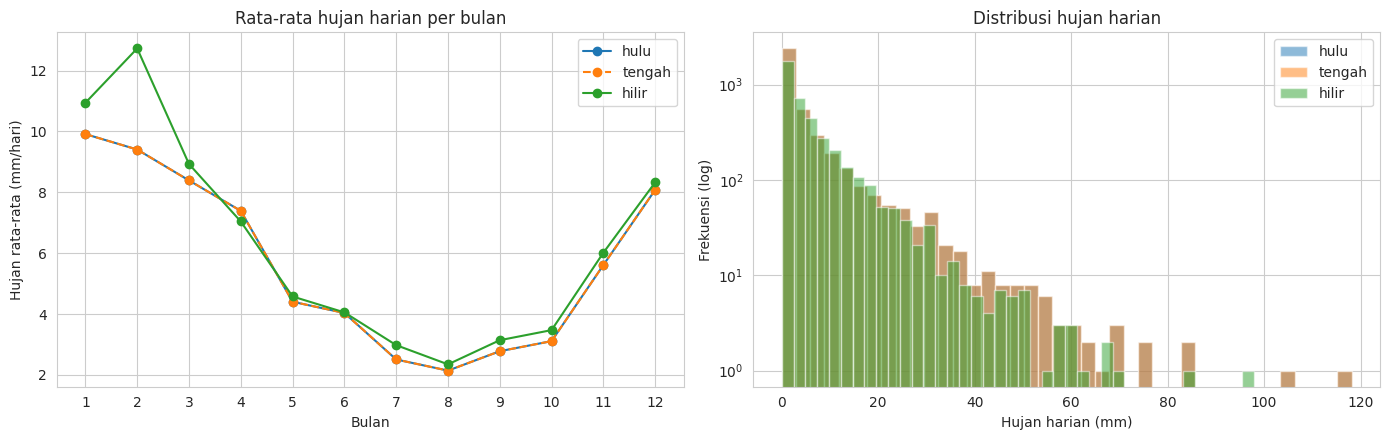

Hujan harian maksimum (mm):
 zona
hilir      97.96
hulu      118.12
tengah    118.12
Name: PRECTOTCORR, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# (kiri) rata-rata hujan harian per bulan, tiga titik
bulanan = (raw.assign(bulan=raw.date.dt.month)
              .groupby(["bulan", "zona"]).PRECTOTCORR.mean().unstack()[ZONES])
for z, ls in zip(ZONES, ["-", "--", "-"]):
    ax[0].plot(bulanan.index, bulanan[z], ls, marker="o", label=z)
ax[0].set(xlabel="Bulan", ylabel="Hujan rata-rata (mm/hari)",
          title="Rata-rata hujan harian per bulan", xticks=range(1, 13))
ax[0].legend()

# (kanan) distribusi hujan harian, sumbu vertikal logaritmik
for z in ZONES:
    ax[1].hist(raw.loc[raw.zona == z, "PRECTOTCORR"], bins=40, alpha=0.5, label=z)
ax[1].set(yscale="log", xlabel="Hujan harian (mm)", ylabel="Frekuensi (log)",
          title="Distribusi hujan harian")
ax[1].legend()
plt.tight_layout(); plt.show()

print("Hujan harian maksimum (mm):\n", raw.groupby("zona").PRECTOTCORR.max().round(2))

## 5. Rekayasa fitur (Subbab 2.3)

Seluruh fitur hanya memakai informasi hari **t**. Terdapat 24 fitur dalam enam kelompok.
Antecedent Precipitation Index dihitung rekursif: $API_t = R_t + k \cdot API_{t-1}$, dengan $k = 0{,}9$ dan $R_t$ = hujan rata-rata antarzona.

In [7]:
rain, gwet = pv("PRECTOTCORR"), pv("GWETTOP")
tmax, tmin, ws, ps = pv("T2M_MAX"), pv("T2M_MIN"), pv("WS2M"), pv("PS")

F = pd.DataFrame(index=rain.index)

# 1) Hujan
F["rain_hulu"], F["rain_tengah"], F["rain_hilir"] = rain["hulu"], rain["tengah"], rain["hilir"]
F["rain_mean"] = rain.mean(axis=1)
F["rain_max"] = rain.max(axis=1)

# 2) Lag dan akumulasi
for l in (1, 2, 3):
    F[f"rain_max_lag{l}"] = F["rain_max"].shift(l)
F["rain_hulu_lag1"] = F["rain_hulu"].shift(1)
F["rain_hulu_lag2"] = F["rain_hulu"].shift(2)
F["rain_tengah_lag1"] = F["rain_tengah"].shift(1)
F["rain_mean_sum3"] = F["rain_mean"].rolling(3).sum()
F["rain_mean_sum7"] = F["rain_mean"].rolling(7).sum()

# 3) Antecedent Precipitation Index (rekursif, k = 0,9)
r = F["rain_mean"].to_numpy()
api = np.empty_like(r)
api[0] = r[0]
for i in range(1, len(r)):
    api[i] = r[i] + API_K * api[i - 1]
F["api_k09"] = api

# 4) Kondisi tanah
F["gwet_hulu"], F["gwet_hilir"] = gwet["hulu"], gwet["hilir"]
F["gwet_mean"] = gwet.mean(axis=1)
F["gwet_mean_lag1"] = F["gwet_mean"].shift(1)

# 5) Atmosfer
F["tmax_mean"], F["tmin_mean"] = tmax.mean(axis=1), tmin.mean(axis=1)
F["ws_mean"], F["ps_mean"] = ws.mean(axis=1), ps.mean(axis=1)

# 6) Musiman
doy = F.index.dayofyear.to_numpy()
F["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
F["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

FEATURES = list(F.columns)
assert len(FEATURES) == 24, f"Jumlah fitur {len(FEATURES)} != 24"
print(len(FEATURES), "fitur:", FEATURES)

24 fitur: ['rain_hulu', 'rain_tengah', 'rain_hilir', 'rain_mean', 'rain_max', 'rain_max_lag1', 'rain_max_lag2', 'rain_max_lag3', 'rain_hulu_lag1', 'rain_hulu_lag2', 'rain_tengah_lag1', 'rain_mean_sum3', 'rain_mean_sum7', 'api_k09', 'gwet_hulu', 'gwet_hilir', 'gwet_mean', 'gwet_mean_lag1', 'tmax_mean', 'tmin_mean', 'ws_mean', 'ps_mean', 'doy_sin', 'doy_cos']


## 6. Target klasifikasi t+1 (Subbab 2.4)

Target adalah kelas hujan **esok hari** berdasarkan hujan terbesar di antara tiga zona (`rain_max` pada t+1).
Baris awal (akibat lag/jendela bergulir) dan baris terakhir (tanpa hari esok) dibuang.

In [8]:
data = F.copy()
data["rain_next"] = F["rain_max"].shift(-1)          # hujan maksimum antarzona hari t+1
data = data.dropna().copy()                          # buang 6 baris awal + 1 baris akhir

# Kelas BMKG: [<5), [5,20), [20,50), [>=50)
data["y"] = pd.cut(data["rain_next"], bins=BINS, labels=False, right=False).astype(int)

# Aturan penggabungan kelas teratas bila sampel latih < MIN_TRAIN_TOP
is_train = data.index <= TRAIN_END
class_names = list(CLASS_NAMES)
while len(class_names) > 2 and (data.loc[is_train, "y"] == len(class_names) - 1).sum() < MIN_TRAIN_TOP:
    top = len(class_names) - 1
    print(f"Kelas {top} < {MIN_TRAIN_TOP} sampel latih, digabung dengan kelas {top-1}")
    data["y"] = data["y"].clip(upper=top - 1)
    class_names = class_names[:-1]
    class_names[-1] += " (gabungan)"
LABELS = list(range(len(class_names)))

print(f"Sampel akhir: {len(data)}  ({data.index.min().date()} s.d. {data.index.max().date()})")
print("Jumlah kelas :", len(class_names))

Sampel akhir: 4011  (2015-01-07 s.d. 2025-12-30)
Jumlah kelas : 4


## 7. Pembagian data kronologis (Subbab 2.5)

In [9]:
idx = data.index
m_train = idx <= TRAIN_END
m_val   = (idx > TRAIN_END) & (idx <= VAL_END)
m_test  = idx > VAL_END

X, y = data[FEATURES], data["y"]
X_train, y_train = X[m_train], y[m_train]
X_val,   y_val   = X[m_val],   y[m_val]
X_test,  y_test  = X[m_test],  y[m_test]

# Tabel 2. Pembagian data
def ringkas(nama, periode, yy):
    row = {"Subset": nama, "Periode": periode, "Jumlah": len(yy)}
    row.update({f"Kelas {k}": int((yy == k).sum()) for k in LABELS})
    return row

tabel2 = pd.DataFrame([ringkas("Latih", "2015-2022", y_train),
                       ringkas("Validasi", "2023", y_val),
                       ringkas("Uji", "2024-2025", y_test)])
print("Tabel 2. Pembagian data")
tabel2

Tabel 2. Pembagian data


,Subset,Periode,Jumlah,Kelas 0,Kelas 1,Kelas 2,Kelas 3
0,Latih,2015-2022,2916,1731,907,248,30
1,Validasi,2023,365,251,85,23,6
2,Uji,2024-2025,730,399,247,80,4


## 8. Pelatihan model (Subbab 2.6)

Ketidakseimbangan kelas ditangani dengan **pembobotan** (tanpa oversampling). Hiperparameter ditetapkan manual sesuai jurnal.

In [10]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=3,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="mlogloss", random_state=SEED, n_jobs=-1),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
}

w_train = compute_sample_weight("balanced", y_train)      # bobot sampel untuk XGBoost
for name, mdl in models.items():
    if name == "XGBoost":
        mdl.fit(X_train, y_train, sample_weight=w_train)
    else:
        mdl.fit(X_train, y_train)
    print(f"[selesai] {name}")

[selesai] Random Forest
[selesai] XGBoost
[selesai] SVM (RBF)


### **Confusion Matrix**

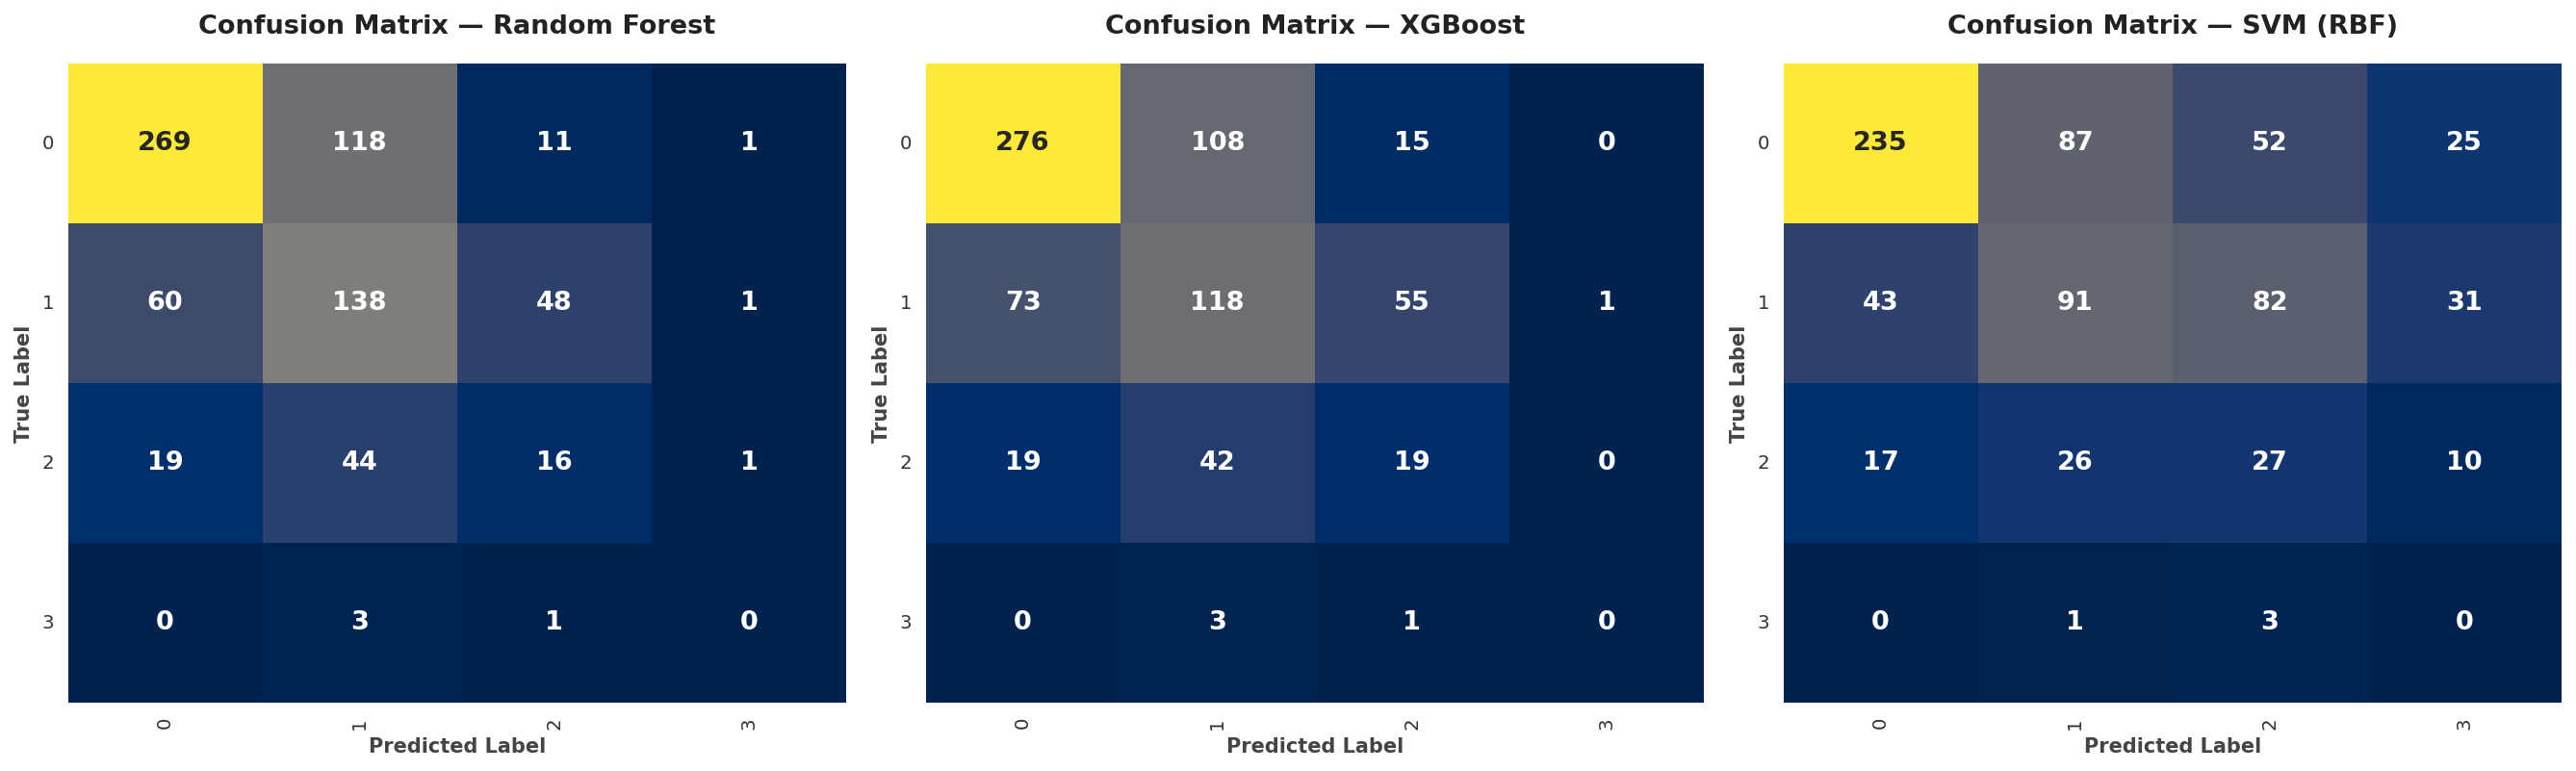

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Hitung Confusion Matrix untuk setiap model
cms = {}
for name, mdl in models.items():
    y_pred = mdl.predict(X_test)
    cms[name] = confusion_matrix(y_test, y_pred)

# 2. Visualisasi Heatmap (3 Model - Warna Medium & Profesional)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=150)
sns.set_theme(style="white")

class_labels = (
    labels
    if "labels" in locals()
    else [str(i) for i in range(len(list(cms.values())[0]))]
)

for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(
        cm,
        annot=True,  # Menampilkan angka di tengah sel
        fmt="d",  # Format angka integer
        cmap="cividis",  # <--- PILIHAN 1: 'cividis' (Biru Dongker ke Kuning Mustard Soft)
        # Atau ganti cmap="crest" (Toska ke Biru Medium - Adem & Elegan)
        linewidths=0,  # Garis pemisah tetap menyatu (full grid)
        linecolor=None,
        square=False,
        cbar=False,
        annot_kws={"size": 13, "weight": "bold"},  # Angka tetap tegas
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax,
    )

    # Styling Judul dan Sumbu Peta
    ax.set_title(
        f"Confusion Matrix — {name}",
        fontsize=13,
        fontweight="bold",
        pad=15,
        color="#222222",
    )
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight="bold", color="#444444")
    ax.set_ylabel("True Label", fontsize=10, fontweight="bold", color="#444444")

    # Diputar 90 derajat untuk sumbu X
    ax.tick_params(axis="x", rotation=90, labelsize=9.5, labelcolor="#333333")
    ax.tick_params(axis="y", rotation=0, labelsize=9.5, labelcolor="#333333")

plt.tight_layout()
plt.show()

## 9. Evaluasi dan pemilihan model (Subbab 2.7 dan 3.2)

Metrik: akurasi, macro-F1, weighted-F1, dan recall makro. Model dipilih berdasarkan **macro-F1 data validasi**.
Baseline pembanding: selalu memprediksi kelas mayoritas (kelas 0).

In [12]:
def hitung(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted", labels=LABELS, zero_division=0),
            "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)}

pred_val, pred_test, rows = {}, {}, []
for name, mdl in models.items():
    pred_val[name], pred_test[name] = mdl.predict(X_val), mdl.predict(X_test)
    mv, mt = hitung(y_val, pred_val[name]), hitung(y_test, pred_test[name])
    rows.append({"Model": name,
                 "Val. akurasi": mv["acc"], "Val. macro-F1": mv["macro_f1"],
                 "Uji akurasi": mt["acc"], "Uji macro-F1": mt["macro_f1"],
                 "Uji weighted-F1": mt["weighted_f1"], "Uji recall (makro)": mt["macro_recall"]})

# Baseline kelas mayoritas (selalu kelas 0)
mv, mt = hitung(y_val, np.zeros(len(y_val), int)), hitung(y_test, np.zeros(len(y_test), int))
rows.append({"Model": "Baseline mayoritas",
             "Val. akurasi": mv["acc"], "Val. macro-F1": mv["macro_f1"],
             "Uji akurasi": mt["acc"], "Uji macro-F1": mt["macro_f1"],
             "Uji weighted-F1": mt["weighted_f1"], "Uji recall (makro)": mt["macro_recall"]})

tabel3 = pd.DataFrame(rows).set_index("Model")

# Pemilihan model: macro-F1 VALIDASI (bukan uji)
best_name = tabel3.drop(index="Baseline mayoritas")["Val. macro-F1"].idxmax()
best_model = models[best_name]
print(f"Model terpilih (macro-F1 validasi tertinggi): {best_name}\n")
print("Tabel 3. Kinerja model pada data validasi dan uji")
tabel3.round(3).style.apply(
    lambda r: ["font-weight: bold" if r.name == best_name else "" for _ in r], axis=1)

Model terpilih (macro-F1 validasi tertinggi): XGBoost

Tabel 3. Kinerja model pada data validasi dan uji


,Val. akurasi,Val. macro-F1,Uji akurasi,Uji macro-F1,Uji weighted-F1,Uji recall (makro)
Model,,,,,,
Random Forest,0.690000,0.366000,0.579000,0.357000,0.586000,0.358000
XGBoost,0.668000,0.367000,0.566000,0.350000,0.572000,0.352000
SVM (RBF),0.625000,0.350000,0.484000,0.325000,0.531000,0.324000
Baseline mayoritas,0.688000,0.204000,0.547000,0.177000,0.386000,0.250000


### Tambahan opsional: baseline persistensi (belum ada di jurnal)

Prediksi kelas esok hari = kelas hujan maksimum **hari ini**. Reviewer biasanya menanyakan pembanding ini.
Jika dipakai, perbarui Subbab 2.7, Tabel 3, Subbab 3.2, dan keterbatasan nomor 4 pada jurnal.

In [13]:
kelas_hari_ini = pd.cut(data["rain_max"], bins=BINS, labels=False, right=False).astype(int)
if len(LABELS) < 4:                                    # ikuti penggabungan kelas bila terjadi
    kelas_hari_ini = kelas_hari_ini.clip(upper=len(LABELS) - 1)
persist = pd.DataFrame({
    "Val.": hitung(y_val,  kelas_hari_ini[m_val]),
    "Uji":  hitung(y_test, kelas_hari_ini[m_test]),
}).T.rename(columns={"acc": "akurasi", "macro_f1": "macro-F1",
                     "weighted_f1": "weighted-F1", "macro_recall": "recall makro"})
print("Baseline persistensi")
persist.round(3)

Baseline persistensi


,akurasi,macro-F1,weighted-F1,recall makro
Val.,0.674,0.355,0.674,0.355
Uji,0.596,0.364,0.596,0.364


## 10. Kinerja per kelas model terpilih (Subbab 3.3)

In [14]:
rep = classification_report(y_test, pred_test[best_name], labels=LABELS,
                            target_names=class_names, output_dict=True, zero_division=0)
tabel4 = (pd.DataFrame(rep).T
            .rename(columns={"precision": "Presisi", "recall": "Recall",
                             "f1-score": "F1", "support": "Jumlah"})
            .rename(index={"macro avg": "Rata-rata makro"})
            .drop(index=["accuracy", "weighted avg"]))
tabel4["Jumlah"] = tabel4["Jumlah"].astype(int)
print(f"Tabel 4. Kinerja per kelas, {best_name} (data uji 2024-2025)")
tabel4.round(2)

Tabel 4. Kinerja per kelas, XGBoost (data uji 2024-2025)


,Presisi,Recall,F1,Jumlah
0: Tidak/sangat ringan (<5 mm),0.75,0.69,0.72,399
1: Ringan (5-20 mm),0.44,0.48,0.46,247
2: Sedang (20-50 mm),0.21,0.24,0.22,80
3: Lebat (>=50 mm),0.00,0.00,0.00,4
Rata-rata makro,0.35,0.35,0.35,730


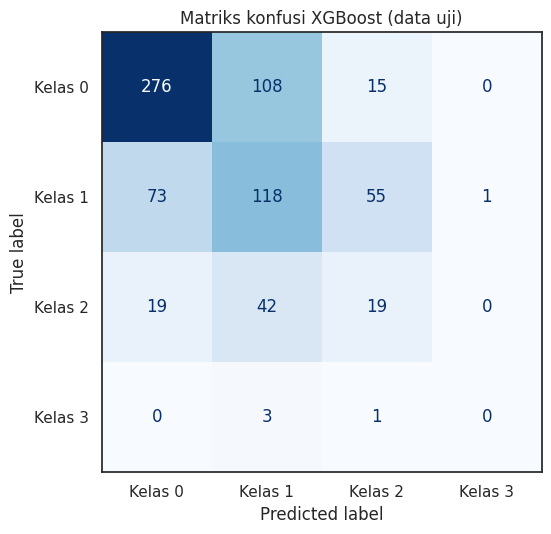

Prediksi salah          : 317
  jatuh ke kelas bersebelahan: 279 (88.0%)
Kelas 2: 61 dari 80 hari (76.2%) diprediksi ke kelas lebih rendah


In [15]:
cm = confusion_matrix(y_test, pred_test[best_name], labels=LABELS)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm, display_labels=[f"Kelas {k}" for k in LABELS]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Matriks konfusi {best_name} (data uji)")
ax.grid(False); plt.tight_layout(); plt.show()

# Ringkasan pola kesalahan
n_salah = int(cm.sum() - np.trace(cm))
n_bersebelahan = int(sum(cm[i, j] for i in LABELS for j in LABELS if abs(i - j) == 1))
print(f"Prediksi salah          : {n_salah}")
print(f"  jatuh ke kelas bersebelahan: {n_bersebelahan} ({100*n_bersebelahan/n_salah:.1f}%)")
if len(LABELS) >= 3:
    k = 2
    n_k = int(cm[k].sum()); rendah = int(cm[k, :k].sum())
    print(f"Kelas {k}: {rendah} dari {n_k} hari ({100*rendah/n_k:.1f}%) diprediksi ke kelas lebih rendah")

## 11. Pengaruh perbedaan distribusi antarperiode (Subbab 3.4)

In [16]:
dist = pd.DataFrame({
    "Latih (2015-2022)": y_train.value_counts(normalize=True),
    "Validasi (2023)":   y_val.value_counts(normalize=True),
    "Uji (2024-2025)":   y_test.value_counts(normalize=True),
}).reindex(LABELS).fillna(0) * 100
dist.index = [f"Kelas {k}" for k in dist.index]
print("Proporsi kelas per periode (%)")
dist.round(1)

Proporsi kelas per periode (%)


,Latih (2015-2022),Validasi (2023),Uji (2024-2025)
Kelas 0,59.4,68.8,54.7
Kelas 1,31.1,23.3,33.8
Kelas 2,8.5,6.3,11.0
Kelas 3,1.0,1.6,0.5


## 12. Kepentingan fitur (Subbab 3.5)

*Permutation importance* pada data uji (20 pengulangan, skor macro-F1) untuk model terpilih.

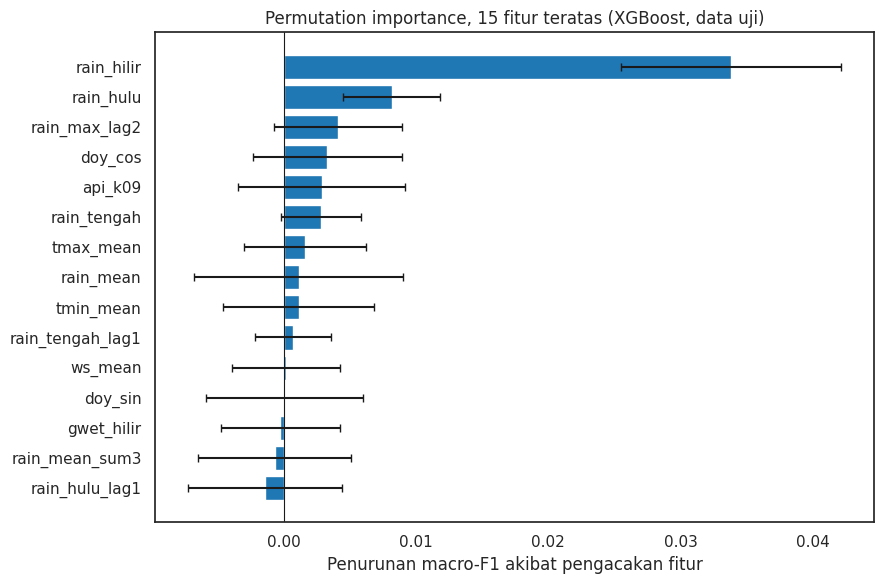

,fitur,mean,std
0,rain_hilir,0.0338,0.0083
1,rain_hulu,0.0082,0.0037
2,rain_max_lag2,0.0041,0.0048
3,doy_cos,0.0033,0.0056
4,api_k09,0.0029,0.0063
5,rain_tengah,0.0028,0.0030
6,tmax_mean,0.0016,0.0046
7,rain_mean,0.0011,0.0079
8,tmin_mean,0.0011,0.0057
9,rain_tengah_lag1,0.0007,0.0029


In [17]:
pi = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                            n_repeats=20, random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({"fitur": FEATURES, "mean": pi.importances_mean, "std": pi.importances_std})
         .sort_values("mean", ascending=False).reset_index(drop=True))

top15 = imp.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top15["fitur"], top15["mean"], xerr=top15["std"], color="#1f77b4", capsize=3)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Penurunan macro-F1 akibat pengacakan fitur")
plt.title(f"Permutation importance, 15 fitur teratas ({best_name}, data uji)")
plt.tight_layout(); plt.show()
imp.head(15).round(4)

## 13. Simpan model dan tabel hasil

In [18]:
joblib.dump({"model": best_model, "nama_model": best_name, "fitur": FEATURES,
             "kelas": class_names}, f"{OUT_DIR}/best_model.pkl")

tabel1.to_csv(f"{OUT_DIR}/tabel1_deskriptif.csv")
tabel2.to_csv(f"{OUT_DIR}/tabel2_split.csv", index=False)
tabel3.round(4).to_csv(f"{OUT_DIR}/tabel3_kinerja.csv")
tabel4.round(4).to_csv(f"{OUT_DIR}/tabel4_per_kelas.csv")
imp.to_csv(f"{OUT_DIR}/permutation_importance.csv", index=False)
print("Tersimpan di folder:", OUT_DIR, "->", sorted(os.listdir(OUT_DIR)))

Tersimpan di folder: output -> ['best_model.pkl', 'permutation_importance.csv', 'tabel1_deskriptif.csv', 'tabel2_split.csv', 'tabel3_kinerja.csv', 'tabel4_per_kelas.csv']
